# WiFi or Data? — Data-Driven Analysis for Smarter Internet Spending
## Bagian 2: Cost-Benefit Analysis, Visualisasi, serta Insight & Rekomendasi (Tahap 5 - 7)

**Penulis / Analis:** Evan Rafa Radya Alifian  
**Lokasi:** Bangkalan, Madura  
**Metode:** Cost-Benefit Analysis (CBA), Break-Even Point (BEP) Analysis, Data Visualization, dan Multi-Scenario Evaluation.

---

### Deskripsi Proyek
Proyek ini bertujuan untuk mengevaluasi secara kuantitatif apakah berlangganan Wi-Fi rumah (seperti IndiHome, Biznet, XL SATU, dll.) lebih hemat dan menguntungkan dibandingkan terus bergantung pada paket internet seluler harian/bulanan. 

Pada tahap 1–4 sebelumnya, telah dilakukan pendefinisian masalah, pengumpulan data, pembersihan data (data cleaning), dan analisis eksploratif data (EDA). Notebook ini secara khusus melanjutkan ke **Tahap 5 hingga 7**:
1. **Tahap 5: Cost-Benefit Analysis (CBA) & Break-Even Analysis**
2. **Tahap 6: Visualisasi Data Skenario & Titik Impas**
3. **Tahap 7: Insights & Strategic Recommendations**

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Set style visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

print("Library berhasil di-import.")

Library berhasil di-import.


---
## Load Cleaned Datasets
Mengunggah data yang telah dibersihkan pada tahap 3-4 dari direktori `datasets/clean/`.

In [37]:
# Load data
df_mobile = pd.read_csv('../datasets/clean/mobile_transactions_clean.csv')
df_wifi = pd.read_csv('../datasets/clean/wifi_offers_clean.csv')
df_usage = pd.read_csv('../datasets/clean/usage_log_clean.csv')
df_scenarios = pd.read_csv('../datasets/clean/scenario_inputs_clean.csv')

print("=== Summary Datasets Loaded ===")
print(f"Mobile Transactions: {len(df_mobile)} baris")
print(f"WiFi Offers: {len(df_wifi)} baris")
print(f"Usage Logs: {len(df_usage)} baris")
print(f"Scenario Inputs: {len(df_scenarios)} baris")

=== Summary Datasets Loaded ===
Mobile Transactions: 34 baris
WiFi Offers: 53 baris
Usage Logs: 21 baris
Scenario Inputs: 84 baris


---
## Tahap 5: Cost-Benefit Analysis (CBA) & Break-Even Point (BEP)

### Formulasi Matematika Analisis
1. **Total Biaya Internet Seluler ($TC_{mobile}$):**
   $$TC_{mobile}(m, n) = m \times n \times C_{mobile}$$
   *Dimana $m$ = durasi (bulan), $n$ = jumlah pengguna, $C_{mobile}$ = biaya paket seluler per orang/bulan.*

2. **Total Biaya Wi-Fi ($TC_{wifi}$):**
   $$TC_{wifi}(m, n) = C_{install} + m \times C_{wifi} + m \times n \times C_{extra\_mobile}$$
   *Dimana $C_{install}$ = biaya pemasangan awal Wi-Fi, $C_{wifi}$ = biaya langganan Wi-Fi bulanan, $C_{extra\_mobile}$ = paket seluler cadangan untuk mobilitas di luar rumah (misal: Rp20.000/orang/bulan).*

3. **Penghematan Bersih / Net Savings ($NS$):**
   $$NS(m, n) = TC_{mobile}(m, n) - TC_{wifi}(m, n)$$

4. **Biaya per Orang / Cost Per User ($CPU$):**
   $$CPU_{wifi}(m, n) = \frac{TC_{wifi}(m, n)}{n}$$

5. **Break-Even Point ($m_{BEP}$ - Bulan Titik Impas):**
   $$m_{BEP} = \frac{C_{install}}{n \times (C_{mobile} - C_{extra\_mobile}) - C_{wifi}}$$

In [38]:
# Kalkulasi Detail pada Dataset Scenario Inputs
df_calc = df_scenarios.copy()

# Total Biaya Kumulatif
df_calc['total_mobile_cost'] = df_calc['months'] * df_calc['users'] * df_calc['mobile_cost']
df_calc['total_wifi_cost'] = df_calc['installation_cost'] + (df_calc['months'] * df_calc['wifi_cost']) + (df_calc['months'] * df_calc['users'] * df_calc['extra_mobile_cost'])

# Penghematan Bersih (Net Savings)
df_calc['net_savings'] = df_calc['total_mobile_cost'] - df_calc['total_wifi_cost']

# Biaya per Orang per Bulan
df_calc['mobile_cost_per_user_monthly'] = df_calc['mobile_cost']
df_calc['wifi_cost_per_user_monthly'] = df_calc['total_wifi_cost'] / (df_calc['months'] * df_calc['users'])

# Status Keputusan
df_calc['recommendation'] = np.where(df_calc['net_savings'] > 0, 'Wi-Fi Hemat', 'Seluler Hemat')

# Tampilkan ringkasan skenario
print("=== Sampel Kalkulasi Cost-Benefit Skenario ===")
display_cols = ['scenario_id', 'users', 'months', 'total_mobile_cost', 'total_wifi_cost', 'net_savings', 'wifi_cost_per_user_monthly', 'recommendation']
print(df_calc[display_cols].head(12).to_string(index=False))

=== Sampel Kalkulasi Cost-Benefit Skenario ===
scenario_id  users  months  total_mobile_cost  total_wifi_cost  net_savings  wifi_cost_per_user_monthly recommendation
       S001      1       3             399000           970000      -571000               323333.333333  Seluler Hemat
       S002      1       6             798000          1690000      -892000               281666.666667  Seluler Hemat
       S003      1      12            1596000          3130000     -1534000               260833.333333  Seluler Hemat
       S004      1      24            3192000          6010000     -2818000               250416.666667  Seluler Hemat
       S005      2       3             798000          1030000      -232000               171666.666667  Seluler Hemat
       S006      2       6            1596000          1810000      -214000               150833.333333  Seluler Hemat
       S007      2      12            3192000          3370000      -178000               140416.666667  Seluler Hemat
 

In [39]:
# Kalkulasi Break-Even Point (BEP) Eksplisif berdasarkan Jumlah Pengguna
def calculate_bep_months(users, mobile_cost=133000, wifi_cost=220000, install_cost=250000, extra_mobile=20000):
    monthly_net_saving_per_group = users * (mobile_cost - extra_mobile) - wifi_cost
    if monthly_net_saving_per_group <= 0:
        return np.nan # Tidak akan pernah BEP (Seluler selalu lebih murah)
    return install_cost / monthly_net_saving_per_group

bep_results = []
for u in range(1, 6):
    bep_m = calculate_bep_months(u)
    bep_results.append({
        'Jumlah Pengguna': f"{u} Orang",
        'Biaya Seluler Total/Bln': f"Rp {u * 133000:,}",
        'Biaya Wi-Fi Total/Bln (inc. extra)': f"Rp {220000 + (u*20000):,}",
        'Selisih Bulanan': f"Rp {(u * 113000) - 220000:,}",
        'Bulan Titik Impas (BEP)': f"{bep_m:.2f} Bulan" if not np.isnan(bep_m) else "Tidak Pernah Impas"
    })

df_bep_summary = pd.DataFrame(bep_results)
print("=== Ringkasan Titik Impas (Break-Even Point) ===")
print(df_bep_summary.to_string(index=False))

=== Ringkasan Titik Impas (Break-Even Point) ===
Jumlah Pengguna Biaya Seluler Total/Bln Biaya Wi-Fi Total/Bln (inc. extra) Selisih Bulanan Bulan Titik Impas (BEP)
        1 Orang              Rp 133,000                         Rp 240,000     Rp -107,000      Tidak Pernah Impas
        2 Orang              Rp 266,000                         Rp 260,000        Rp 6,000             41.67 Bulan
        3 Orang              Rp 399,000                         Rp 280,000      Rp 119,000              2.10 Bulan
        4 Orang              Rp 532,000                         Rp 300,000      Rp 232,000              1.08 Bulan
        5 Orang              Rp 665,000                         Rp 320,000      Rp 345,000              0.72 Bulan


---
## Tahap 6: Data Visualization & Visual Insights

Pada tahap ini dibuat visualisasi komprehensif untuk menyajikan perbandingan biaya, titik impas, dan efisiensi Wi-Fi vs Data Seluler.

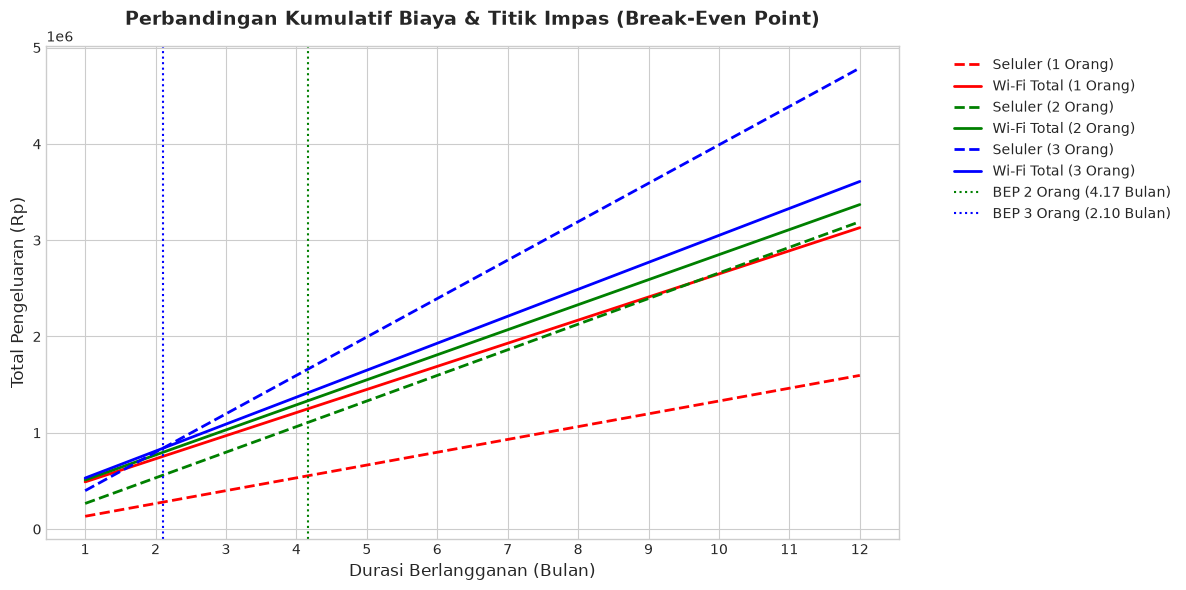

In [40]:
# Visualisasi 1: Kurva Titik Impas (Break-Even Point) 1 Orang vs 2 Orang vs 3 Orang (1-12 Bulan)
months_range = np.arange(1, 13)

plt.figure(figsize=(12, 6))

# Skenario 1 Pengguna
mobile_cost_1 = months_range * 1 * 133000
wifi_cost_1 = 250000 + (months_range * 220000) + (months_range * 1 * 20000)

# Skenario 2 Pengguna
mobile_cost_2 = months_range * 2 * 133000
wifi_cost_2 = 250000 + (months_range * 220000) + (months_range * 2 * 20000)

# Skenario 3 Pengguna
mobile_cost_3 = months_range * 3 * 133000
wifi_cost_3 = 250000 + (months_range * 220000) + (months_range * 3 * 20000)

plt.plot(months_range, mobile_cost_1, 'r--', label='Seluler (1 Orang)', linewidth=2)
plt.plot(months_range, wifi_cost_1, 'r-', label='Wi-Fi Total (1 Orang)', linewidth=2)

plt.plot(months_range, mobile_cost_2, 'g--', label='Seluler (2 Orang)', linewidth=2)
plt.plot(months_range, wifi_cost_2, 'g-', label='Wi-Fi Total (2 Orang)', linewidth=2)

plt.plot(months_range, mobile_cost_3, 'b--', label='Seluler (3 Orang)', linewidth=2)
plt.plot(months_range, wifi_cost_3, 'b-', label='Wi-Fi Total (3 Orang)', linewidth=2)

plt.axvline(x=4.17, color='green', linestyle=':', label='BEP 2 Orang (4.17 Bulan)')
plt.axvline(x=2.10, color='blue', linestyle=':', label='BEP 3 Orang (2.10 Bulan)')

plt.title('Perbandingan Kumulatif Biaya & Titik Impas (Break-Even Point)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Durasi Berlangganan (Bulan)', fontsize=12)
plt.ylabel('Total Pengeluaran (Rp)', fontsize=12)
plt.xticks(months_range)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

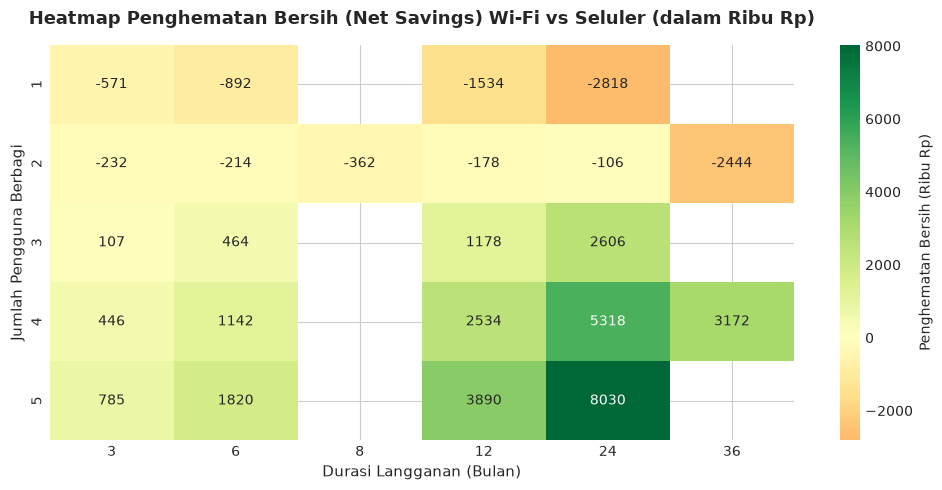

In [41]:
# Visualisasi 2: Heatmap Penghematan Bersih (Net Savings) Berdasarkan Pengguna & Durasi
df_calc_clean = df_calc.drop_duplicates(subset=["users", "months"])

pivot_savings = df_calc_clean.pivot(
    index="users", columns="months", values="net_savings"
)

plt.figure(figsize=(10, 5))
sns.heatmap(
    pivot_savings / 1000,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    center=0,
    cbar_kws={"label": "Penghematan Bersih (Ribu Rp)"},
)
plt.title(
    "Heatmap Penghematan Bersih (Net Savings) Wi-Fi vs Seluler (dalam Ribu Rp)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Durasi Langganan (Bulan)", fontsize=11)
plt.ylabel("Jumlah Pengguna Berbagi", fontsize=11)
plt.tight_layout()
plt.show()

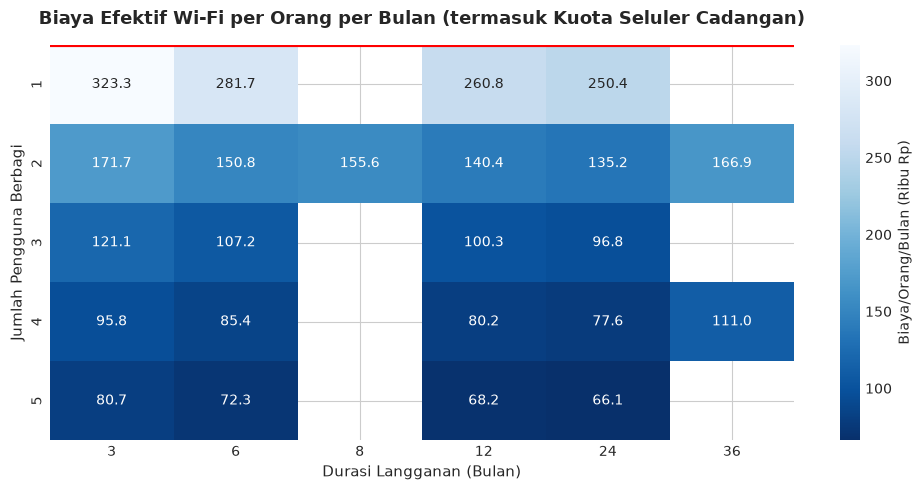

In [42]:
# Visualisasi 3: Biaya Bulanan Efektif per Orang (Cost per User per Month)
# Gunakan df_calc_clean yang sudah dihapus duplikatnya
pivot_cpu = df_calc_clean.pivot(
    index="users", columns="months", values="wifi_cost_per_user_monthly"
)

plt.figure(figsize=(10, 5))
sns.heatmap(
    pivot_cpu / 1000,
    annot=True,
    fmt=".1f",
    cmap="Blues_r",
    cbar_kws={"label": "Biaya/Orang/Bulan (Ribu Rp)"},
)
plt.axhline(y=0, color="red", linewidth=3, label="Biaya Seluler Tunggal (Rp 133k)")
plt.title(
    "Biaya Efektif Wi-Fi per Orang per Bulan (termasuk Kuota Seluler Cadangan)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Durasi Langganan (Bulan)", fontsize=11)
plt.ylabel("Jumlah Pengguna Berbagi", fontsize=11)
plt.tight_layout()
plt.show()

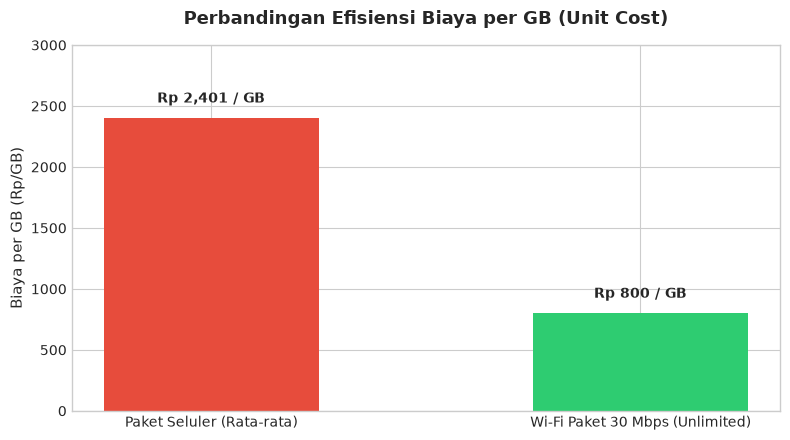

In [43]:
# Visualisasi 4: Perbandingan Kuota & Cost per GB (Seluler vs Wi-Fi Unlimited)
# Asumsi konsumsi bulanan pribadi ~ 40 GB dari usage log
avg_usage_gb = df_usage['data_used_gb'].mean() * 30 if len(df_usage) > 0 else 40.0

categories = ['Paket Seluler (Rata-rata)', 'Wi-Fi Paket 30 Mbps (Unlimited)']
cost_per_gb = [(133000 / avg_usage_gb), (240000 / 300)] # Menggunakan asumsi 300 GB fair usage Wi-Fi

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(categories, cost_per_gb, color=['#e74c3c', '#2ecc71'], width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'Rp {yval:,.0f} / GB', ha='center', va='bottom', fontweight='bold')

ax.set_ylabel('Biaya per GB (Rp/GB)', fontsize=11)
ax.set_title('Perbandingan Efisiensi Biaya per GB (Unit Cost)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, max(cost_per_gb) * 1.25)
plt.tight_layout()
plt.show()

---
## Tahap 7: Insights & Strategic Recommendations

### 1. Key Insights dari Analisis Data
* **Pengeluaran Internet Seluler:** Rata-rata pengeluaran internet seluler pribadi mencapai **Rp 133.000 / bulan**.
* **Ambang Pengguna Tunggal (Single-User Threshold):**
  * Bagi **1 orang (pengguna tunggal)** yang tinggal sendiri, berlangganan Wi-Fi mandiri (Rp 220.000/bulan + Rp 20.000 ekstra seluler = Rp 240.000/bulan) **tidak pernah mencapai titik impas (BEP)**. Seluler tetap secara finansial lebih hemat Rp 107.000/bulan dibandingkan Wi-Fi single-user.
* **Titik Impas Pengguna Bersama (Multi-User Break-Even):**
  * **2 Pengguna (Sharing 2 Orang):** Mencapai Break-Even Point pada **bulan ke-4.17 (~4 bulan 5 hari)**. Setelah bulan ke-4, Wi-Fi memberikan penghematan bersih bulanan sebesar Rp 6.000/bulan (atau hemat total Rp 226.000 pada bulan ke-12).
  * **3+ Pengguna (Sharing 3-4 Orang):** Sangat menguntungkan. BEP dicapai sangat cepat pada **bulan ke-2.10 (~2 bulan 3 hari)**. Pada bulan ke-12, penghematan mencapai **Rp 944.000** (untuk 3 orang) dan **Rp 1.662.000** (untuk 4 orang).

---

### 2. Matrix Rekomendasi Berbasis Skenario Pengguna

| Skenario Pengguna | Rekomendasi Utama | Asumsi Biaya Efektif / Orang | Justifikasi / Pertimbangan Pertambahan Nilai |
| :--- | :--- | :--- | :--- |
| **Skenario A: Tinggal Sendiri (Solo / Kost)** | **Tetap Paket Seluler** | Rp 133.000 / bulan | Wi-Fi memerlukan biaya Rp 240.000/bulan (rugi Rp 107k/bln). Tetap seluler kecuali butuh kuota > 100GB/bln untuk kerja heavy streaming/coding. |
| **Skenario B: Berdua (Kost Berdua / Pasangan)** | **Berlangganan Wi-Fi** | Rp 130.000 / orang / bulan (setelah bulan ke-4) | BEP dicapai di bulan ke-4. Biaya per orang menjadi lebih murah dibanding paket seluler individu + dapat kecepatan internet stabil tanpa batas kuota. |
| **Skenario C: Berkelompok (3-4 Orang / Rumah/Kost)** | **Sangat Disarankan Wi-Fi** | Rp 70.000 – Rp 93.000 / orang / bulan | BEP sangat cepat (2 bulan). Menghemat hingga > Rp 900rb/tahun per kelompok. Sangat efisien untuk belajar & hiburan bersama. |
| **Skenario D: Tingkat Mobilitas Tinggi** | **Paket Seluler (Hybrid jika > 2 orang)** | Rp 133.000 / bulan | Pengguna yang 80% waktunya berada di luar rumah/kampus tidak dapat memanfaatkan Wi-Fi rumah secara optimal. |

---

### 3. Panduan Keputusan Praktis (Decision Framework)
1. **Aturan Utama (Rule of Thumb):** Jika jumlah penghuni rumah/kost yang aktif mengonfirmasi berbagi biaya $\ge 2$ orang dan berencana menetap $\ge 6$ bulan, **segera pasang Wi-Fi**.
2. **Paket Wi-Fi Direkomendasikan di Bangkalan:** Pilih paket internet-only 30 Mbps dengan kisaran harga bulanan Rp 220.000 – Rp 280.000 (bebas dari bundling TV yang tidak diperlukan).
3. **Dana Cadangan Seluler:** Tetap sisihkan **Rp 20.000 / bulan** untuk paket data seluler minimalis guna menjaga konektivitas navigasi/chat saat berada di luar jangkauan Wi-Fi.